# Preliminaries

Predictions and explanations on the test set using the library `Xplique`. These will be the test samples for the `jsPsych` experiment.

In [1]:
!pwd
import sys
sys.path.append('./xplique/')
sys.path.append('./wingbeats/')

/mnt/KInsektDaten/teo


In [2]:
import tensorflow as tf
print(tf.__version__)
print(tf.config.list_physical_devices('GPU'))

2.8.1
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
import numpy as np
from matplotlib import pyplot as plt
from tensorflow.keras.layers.experimental.preprocessing import Rescaling

from beexplainable.beexplainable.utils import metafile_readers as mr # an extra prefix beexplainable. may be needed
from beexplainable.beexplainable.modelling import classifiers as cls
from beexplainable.beexplainable.preprocessing import parsers as ps
from wingbeats import modelling as wm # for building simple classifiers

from xplique.plots import plot_attributions, plot_attribution

2022-10-18 12:43:47.863677: I tensorflow/core/platform/cpu_feature_guard.cc:151] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE4.1 SSE4.2 AVX AVX2 AVX512F FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2022-10-18 12:43:48.313200: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1525] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 47187 MB memory:  -> device: 0, name: Quadro RTX 8000, pci bus id: 0000:65:00.0, compute capability: 7.5


In [4]:
#compress_B_lucorum = True  # compress the 4 difficult species together

metafolder = './beexplainable/metafiles/Bees_Christian/'
spec_subfolder = '22_species/'

BEES_PATH = '../data/data_lstudio/Bees_Christian/'
IMAGES_PATH = metafolder + 'images.txt'
IMAGES_LABELS_PATH = metafolder + spec_subfolder + 'image_class_labels.txt'
CLASSES_PATH = metafolder + spec_subfolder + 'classes.txt'

MODELS_PATH  = './beexplainable/models/'
FIGURES_PATH = './beexplainable/jspsych_experiment/img/'

# Load images

In [5]:
batch_size = 64
img_height = img_width = 224

# Read file IDs and corresponding class labels
img_dict = mr.metafile_to_dict(IMAGES_PATH)
img_label_dict = mr.metafile_to_dict(IMAGES_LABELS_PATH)
file_ids = list( img_dict.keys() )
y_true   = list( img_label_dict.values() )
y_true   = np.asarray(y_true, dtype = np.uint8) - 1
# Note! Labels in CUB format start at index 1, but cross entropy needs to start at 0

# Read class names
cls_dict = mr.metafile_to_dict(CLASSES_PATH)
classes = list( cls_dict.values() )

# Pick only 6 classes for the experiments
jspsych_inds = [18, 7, 4, 17, 1, 14] # 0-based
jspsych_classes = np.array(classes)[jspsych_inds]

In [6]:
# Get dictionary of file IDs and file names
# Convert it into a tf.StaticHashTable to be able to retrieve dictionary values during eager execution
# Alternative: tf.gather
img_lookup = tf.lookup.StaticHashTable(tf.lookup.KeyValueTensorInitializer(file_ids,
                                                                           list(img_dict.values())),
                                       default_value = 'No file')

# Parsing function for tf.Dataset
parse_image_lab = lambda file_id, label: (ps.parse_image(file_id, img_lookup, img_width, img_height, BEES_PATH),
                                          label)

In [7]:
# Conversion to tf.Dataset
test_set = ps.parse_to_dataset(file_ids, y_true, parse_image_lab)
test_set = test_set.cache().batch(batch_size).prefetch(tf.data.experimental.AUTOTUNE)

# Normalize raw images (first item in the tuples, second is the mask)
normalization_layer = Rescaling(1./255)
test_set = test_set.map(lambda x, y: (normalization_layer(x), y))

2022-10-18 12:43:51.086947: W tensorflow/core/kernels/data/cache_dataset_ops.cc:768] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


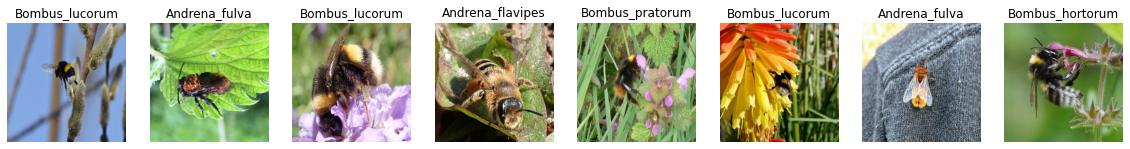

In [8]:
# Plot a few examples
plt.figure(figsize = (20, 20))
num_cols, num_plotted = min(8, batch_size), 0
with tf.device('/CPU:0'):
    for images, labels in test_set.take(1):
        for img, lab in zip(images, labels):
            if lab.numpy() in jspsych_inds and num_plotted < num_cols:
                plt.subplot(1, num_cols, num_plotted+1)
                plt.imshow(img)
                plt.title(cls_dict[str(lab.numpy()+1)])
                plt.axis("off")
                num_plotted += 1
plt.show()

In [9]:
for image_batch, labels_batch in test_set.take(1):
    print(image_batch.shape)
    print(labels_batch[0])

(64, 224, 224, 3)
tf.Tensor(0, shape=(), dtype=uint8)


2022-10-18 12:43:52.595375: W tensorflow/core/kernels/data/cache_dataset_ops.cc:768] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


# Load Model

In [10]:
# Define initial training and other model parameters
drop_rate = 0.5
lr, reg = 1e-4, 1e-4 # parameters optimized in HPO notebook
in_shape = (img_width, img_height, 3)

constructor, out_shape =  wm.build_simple_classifier, len(classes)
loss = 'sparse_categorical_crossentropy'
metrics = ['accuracy', tf.keras.metrics.SparseTopKCategoricalAccuracy(k=3, name='top_3_accuracy')]

# Define whether to load fine grained backbone weights
load_pretrained_backbone = True # if False, ImageNet weights are loaded
# ResNet50 weights trained on iNat2021
# https://github.com/visipedia/newt/tree/main/benchmark
pretrained_weights_file = MODELS_PATH + 'backbones/resnet50_simclr_v1_inat20_no_top_500.h5' if load_pretrained_backbone else None

# Derive model name
input_form = 'raw' # raw, masked, bbox, masked_bbox
#dataset_type = 'mini' if use_mini_dataset else 'all'
init = 'iNat' if load_pretrained_backbone else 'Imagenet'
model_name = 'ResNet50_' + init + '_' + input_form
weights_file = MODELS_PATH + 'all/' + spec_subfolder + model_name + '/' + model_name + '.h5' # path from which to load weights

# The pretrained ResNet on iNat already has a GlobalAvgPooling layer
add_global_avg = False if load_pretrained_backbone else True

# Whether to retrain the backbone or not
trainable = True

In [11]:
# Build and compile
tf.keras.backend.clear_session()
cnn_name = 'CNN_Blocks_' + model_name

cnn = cls.CNN_ResNet50(in_shape, drop_rate, add_global_avg = add_global_avg, trainable = trainable,
                       weights_file = pretrained_weights_file, name = cnn_name)

model = constructor(in_shape, out_shape, cnn, reg,
                    input_name = 'jpg', model_name = model_name)

model.load_weights(weights_file)

model.compile(tf.keras.optimizers.Adam(lr), loss = loss, metrics = metrics)

### Evaluate on test set

In [12]:
model.evaluate(test_set, verbose=1)

2022-10-18 12:43:55.735407: I tensorflow/stream_executor/cuda/cuda_dnn.cc:368] Loaded cuDNN version 8401
2022-10-18 12:43:56.246541: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2022-10-18 12:43:56.247755: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2022-10-18 12:43:56.247788: W tensorflow/stream_executor/gpu/asm_compiler.cc:80] Couldn't get ptxas version string: INTERNAL: Couldn't invoke ptxas --version
2022-10-18 12:43:56.249047: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2022-10-18 12:43:56.249138: W tensorflow/stream_executor/gpu/redzone_allocator.cc:314] INTERNAL: Failed to launch ptxas
Relying on driver to perform ptx compilation. 
Modify $PATH to customize ptxas location.
This message will be only logged once.


12/12 [==============================] - 8s 369ms/step - loss: 29.1787 - accuracy: 0.7631 - top_3_accuracy: 0.9490


[29.17871856689453, 0.7630854249000549, 0.9490358233451843]

# XAI

## Simple example: Saliency Maps

Keep in mind that the **different methods share the same api**:


``` python
explainer = ExplainerClass(model, batch_size, *explainer_params)
explanations = explainer(inputs, labels)
```



In [13]:
# Convert sparse labels into one-hot-vectors
labels_batch_cat = tf.keras.utils.to_categorical(labels_batch, len(classes))

In [14]:
# Make predictions for the test set
preds = np.argmax( model.predict(image_batch, verbose=1), axis=-1 )
print(preds.shape)

2/2 [==============================] - 1s 14ms/step
(64,)


In [15]:
# Strip model of the softmax layer
# Note: For multi-output models cut off layers not responsible for species classif.
model_no_soft = tf.keras.models.Model(model.input, model.layers[-2].output)
model_no_soft.summary()

Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 jpg (InputLayer)            [(None, 224, 224, 3)]     0         
                                                                 
 CNN_Blocks_ResNet50_iNat_ra  (None, 2048)             23561152  
 w (CNN_ResNet50)                                                
                                                                 
 dense_species (Dense)       (None, 22)                45078     
                                                                 
Total params: 23,606,230
Trainable params: 23,553,110
Non-trainable params: 53,120
_________________________________________________________________


In [16]:
from xplique.attributions import Saliency, Rise

# Create an explainer and generate explanations
#explainer = Saliency(model_no_soft)
explainer = Rise(model, nb_samples=1000, batch_size=batch_size) # 4000
explanations = explainer(image_batch, labels_batch_cat) # `explainer.explain(inputs, labels)` also works

In [17]:
# Find indices of batch samples that have a jspsych label
js_ind = np.nonzero( np.in1d(labels_batch, jspsych_inds) )[0]
print(len(js_ind))

imgs_js = tf.gather( image_batch, js_ind )
labs_js = tf.gather( labels_batch, js_ind )
exps_js = tf.gather( explanations, js_ind )
preds_js = tf.gather( preds, js_ind )

25


Method: Rise


<Figure size 1440x1440 with 0 Axes>

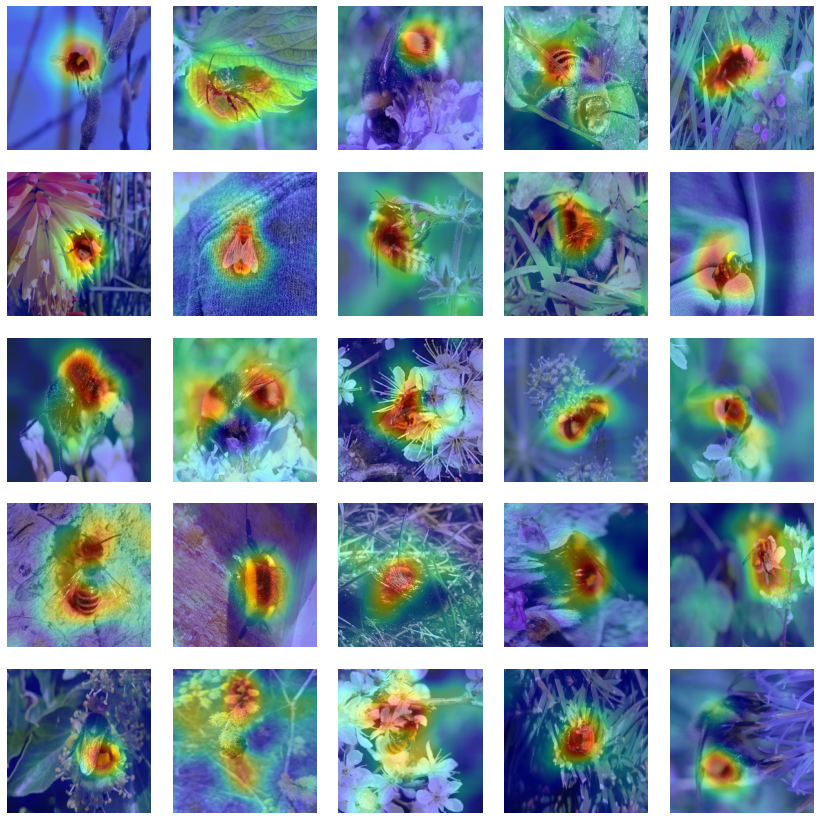

In [18]:
# Plot the test samples for jspsych
num_rows, num_cols, num_plotted = 5, 5, 0
plt.figure(figsize = (20, 20))

print(f"Method: {explainer.__class__.__name__}")
plot_attributions(exps_js, imgs_js, img_size=2., cmap='jet', alpha=0.4,
                  cols=num_cols, absolute_value=True, clip_percentile=0.5)

plt.show()

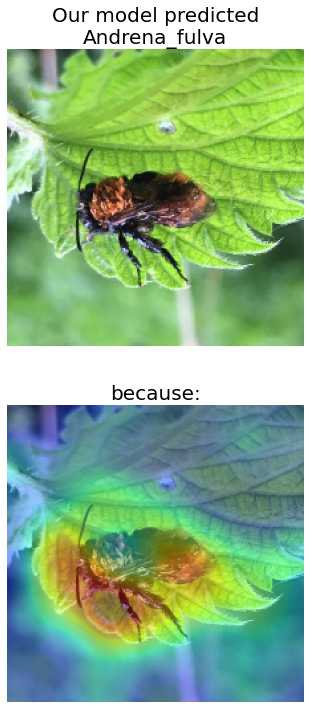

In [22]:
ind, fsize = 1, 20

plt.figure(figsize=(10, 12))
plt.subplot(211)
plt.imshow(imgs_js[ind])
#plt.title('Predicted ' + classes[preds_js[ind]] + '\n True: ' + classes[labs_js[ind].numpy()], fontsize=fsize)
plt.title('Our model predicted\n' + classes[preds_js[ind]], fontsize=fsize)
plt.axis("off")

plt.subplot(212)
plot_attribution(exps_js[ind], imgs_js[ind], cmap='jet', alpha=0.4, absolute_value=True, clip_percentile=0.5)
plt.title('because:', fontsize=fsize)
plt.axis("off")

plt.savefig(FIGURES_PATH + 'rise_' + str(ind) + '.jpg', bbox_inches='tight')
plt.show()

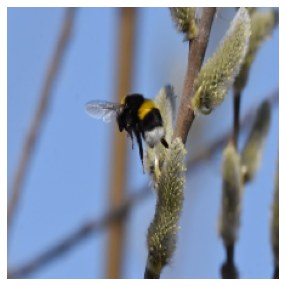

In [20]:
plt.figure(figsize=(5, 5))
plt.imshow(imgs_js[ind])
plt.axis("off")

plt.savefig(FIGURES_PATH + 'nopred_' + str(ind) + '.jpg', bbox_inches='tight')
plt.show()

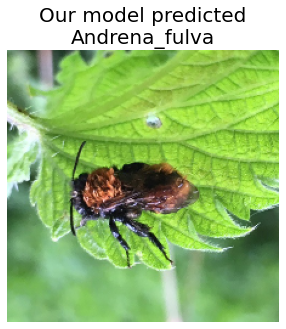

In [23]:
plt.figure(figsize=(5, 5))
plt.imshow(imgs_js[ind])
plt.title('Our model predicted\n' + classes[preds_js[ind]], fontsize=fsize)
plt.axis("off")

plt.savefig(FIGURES_PATH + 'pred_' + str(ind) + '.jpg', bbox_inches='tight')
plt.show()